# PydanticAI together with Pydantic Models

In [28]:
from model import nividia_model
from pydantic_ai import Agent

employee_simulator = Agent(
    model=nividia_model("nvidia/nemotron-3.5-super-vl-120b-a12b"),
    instructions="Du är expert på att simulera anställda i Sverige. Simulerata i detta formatet likt exemplet"
    """
        name:"Berra",
        age 40
        salary: 35000,
        role: "IT-supporter"
        ort: "Göteborg"
    """
    )

result = await employee_simulator.run("Ge mig en data engineer som jobbar i stockholm")

print(result.output)

name: "Erik Johansson",
age: 32,
salary: 52000,
role: "Data Engineer",
ort: "Stockholm"


## Force a structured output using pydantic

In [29]:
from pydantic import BaseModel, Field

class EmployeeModel(BaseModel):
    name: str = Field(description="för och efternamn, inte jättelångt, svenska eller internationella namn")
    age: int = Field(description="ålder från 18 till 67 år", ge=18, le=67)
    salary: int = Field(description="lön mellan 30k-60k, ju mer senior position desto högre lön", 
                        ge=30000, 
                        le=60000
                    )
    role: str = Field(description="yrke/roll")
    description: str = Field(description="Kort beskrivning inom yrket")

employee1 = EmployeeModel(name="Bertil", age=40, salary=30000, role="IT support", description="Hjälper andra anställda med IT")

employee1

EmployeeModel(name='Bertil', age=40, salary=30000, role='IT support', description='Hjälper andra anställda med IT')

In [30]:
employee_simulator = Agent(
    model=nividia_model("nvidia/nemotron-3.5-super-vl-120b-a12b"),
    instructions="Du är expert på att simulera anställda i Sverige"
    )

result = await employee_simulator.run("Ge mig en data engineer i stockholm")

result.output

'Här är en simulerad person som representerar en typisk **Data Engineer i Stockholm**. Den är uppbyggd utifrån vanliga karriärvägar, löner, teknikstackar och svensk arbetsplatskultur.\n\n---\n\n## 👤 Persona: Amanda Eriksson, 32 år\n\n**Titel:** Senior Data Engineer  \n**Företag:** Snabbväxande fintech-bolag i centrala Stockholm (ca 150 anställda)  \n**Anställningsform:** Tillsvidare, heltid  \n**Lön:** Ca 65 000 SEK/månad (brutto), inklusive tjänstepension (ITP) och friskvårdsbidrag  \n**Plats:** Kontor nära Skanstull, hybridarbete (2–3 dagar på kontoret per vecka)  \n**Språk på jobbet:** Huvudsakligen engelska, svenska i pauser och sociala sammanhang\n\n---\n\n### 🎓 Bakgrund\n- **Utbildning:** Civilingenjör i datateknik från KTH Royal Institute of Technology (examen 2016)  \n- **Erfarenhet:** 7 år som data engineer. Började som konsult på ett stort konsultbolag, sedan bytte till produktbolag för att komma närmare verksamheten.\n\n---\n\n### 💻 Teknisk stack (typisk för Stockholm)\n| Om

In [31]:
result = await employee_simulator.run("Ge mig en data engineer i stockholm", output_type=EmployeeModel)

In [32]:
employee2 = result.output

In [33]:
type(employee2)

__main__.EmployeeModel

In [34]:
employee2.name + " är cool"

'Erik Johansson är cool'

In [35]:
employee2.salary

48000

In [36]:
for key, value in employee2.__dict__.items():
    print("{key} : {value}")

{key} : {value}
{key} : {value}
{key} : {value}
{key} : {value}
{key} : {value}


## Simulate many employees

In [37]:
result = await employee_simulator.run("Ge mig totalt 10 anställada inom IT/HR/marketing", output_type=list[EmployeeModel])

result.output

[EmployeeModel(name='Erik Andersson', age=35, salary=45000, role='Systemutvecklare', description='Erfaren fullstack-utvecklare med fokus på .NET och Azure.'),
 EmployeeModel(name='Sofia Karlsson', age=28, salary=38000, role='IT-supporttekniker', description='Ansvarsfull supporttekniker som hanterar användarärenden och hårdvara.'),
 EmployeeModel(name='Amir Hassan', age=42, salary=58000, role='Säkerhetsspecialist', description='Specialiserad på nätverkssäkerhet och riskhantering för företag.'),
 EmployeeModel(name='Elin Berg', age=31, salary=42000, role='HR-koordinator', description='Koordinerar rekrytering, onboarding och personalvård.'),
 EmployeeModel(name='Maria Lundberg', age=49, salary=60000, role='HR-chef', description='Ansvarig för hela HR-avdelningen och strategisk personalplanering.'),
 EmployeeModel(name='Johan Nilsson', age=26, salary=33000, role='Marknadskoordinator', description='Hjälper till med kampanjplanering, mässor och marknadsföringsmaterial.'),
 EmployeeModel(name=

In [38]:
employees = result.output

employees

[EmployeeModel(name='Erik Andersson', age=35, salary=45000, role='Systemutvecklare', description='Erfaren fullstack-utvecklare med fokus på .NET och Azure.'),
 EmployeeModel(name='Sofia Karlsson', age=28, salary=38000, role='IT-supporttekniker', description='Ansvarsfull supporttekniker som hanterar användarärenden och hårdvara.'),
 EmployeeModel(name='Amir Hassan', age=42, salary=58000, role='Säkerhetsspecialist', description='Specialiserad på nätverkssäkerhet och riskhantering för företag.'),
 EmployeeModel(name='Elin Berg', age=31, salary=42000, role='HR-koordinator', description='Koordinerar rekrytering, onboarding och personalvård.'),
 EmployeeModel(name='Maria Lundberg', age=49, salary=60000, role='HR-chef', description='Ansvarig för hela HR-avdelningen och strategisk personalplanering.'),
 EmployeeModel(name='Johan Nilsson', age=26, salary=33000, role='Marknadskoordinator', description='Hjälper till med kampanjplanering, mässor och marknadsföringsmaterial.'),
 EmployeeModel(name=

In [39]:
salary = 0
for employee in employees:
    salary += employee.salary

salary/len(employees)

47000.0

## Convert to dataframe


In [40]:
employees[0].model_dump()

{'name': 'Erik Andersson',
 'age': 35,
 'salary': 45000,
 'role': 'Systemutvecklare',
 'description': 'Erfaren fullstack-utvecklare med fokus på .NET och Azure.'}

In [41]:
import pandas as pd

df = pd.DataFrame([employee.model_dump() for employee in employees])
df.head()

,name,age,salary,role,description
0,Erik Andersson,35,45000,Systemutvecklare,Erfaren fullstack-utvecklare med fokus på .NET...
1,Sofia Karlsson,28,38000,IT-supporttekniker,Ansvarsfull supporttekniker som hanterar använ...
2,Amir Hassan,42,58000,Säkerhetsspecialist,Specialiserad på nätverkssäkerhet och riskhant...
3,Elin Berg,31,42000,HR-koordinator,"Koordinerar rekrytering, onboarding och person..."
4,Maria Lundberg,49,60000,HR-chef,Ansvarig för hela HR-avdelningen och strategis...


In [42]:
df.to_csv("employees.csv", index=None)

<Axes: ylabel='name'>

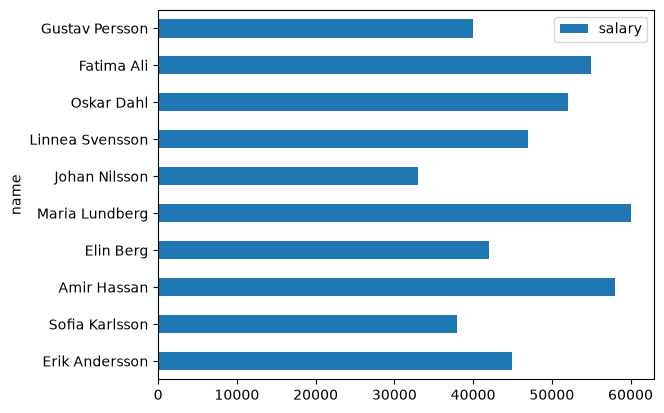

In [44]:
df.plot(kind = "barh", x = "name", y = "salary")